# Final Cell Annotation

Binarization-based marker annotation (scBoolSeq) combined with Leiden-cluster majority-vote label propagation. Moved out of `1. Cell Annotation.ipynb` to isolate the working end-to-end flow from exploratory/alternative methods.


In [22]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))
import warnings
warnings.filterwarnings("ignore") # umap deprecation warnings related to numba do not concern us.

In [23]:
import functools as fn
import itertools as it

import numpy as np
import pandas as pd

import sklearn
from sklearn.utils import Bunch
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.manifold import TSNE
from sklearn.preprocessing import FunctionTransformer
from umap import umap_ as umap

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import plotnine as pn
from plotnine import *

In [24]:
import scanpy as sc

from scboolseq.utils import parse_data_directory, parse_pickles
from scboolseq import scBoolSeq

In [25]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "src"))
from pipeline_config import load_config

cfg = load_config()  # dataset wybierasz w pipeline_config.toml (`active`) albo env BOOLAI_DATASET
print(cfg.describe())

dataset='hsc_4ds' [single dataset (no 1. Cell Annotation / 2. Data Integration)], samples=['young_A', 'young_B', 'old_A', 'old_B'], method='paga_dpt'


## a) Based on binarized states and literature markers

### HVG binarization

Here we import Highy Variable Genes (HVGs) previously identified in `0. Data Preparation.ipynb`.

In [26]:
data = pd.read_csv(cfg.path("hvgs_csv"), index_col=0)
print(data.shape)
data.head()

(2604, 731)


,St18,3110035E14Rik,Mybl1,Tfap2d,Tfap2b,Mcm3,Col9a1,Gulp1,Mstn,Dnah7a,...,Pdlim1,Ina,Pdcd4,Tcf7l2,Gfra1,PISD,Pou4f2,Pax6,Rbp4,Prox1
Lane1_AAACCTGAGATGTCGG,0.000000,0.000000,0.0,0.0,0.0,0.000000,5.724707,0.000000,0.0,0.000000,...,0.0,0.000000,0.000000,4.348158,0.0,0.000000,0.0,5.724707,0.0,0.000000
Lane1_AAACCTGCAATCCAAC,0.000000,0.000000,0.0,0.0,0.0,4.975940,0.000000,0.000000,0.0,0.000000,...,0.0,0.000000,0.000000,4.975940,0.0,0.000000,0.0,4.289671,0.0,4.289671
Lane1_AAACCTGGTTCCTCCA,0.000000,2.482984,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,2.482984,...,0.0,4.888267,2.482984,0.000000,0.0,0.000000,0.0,3.804611,0.0,0.000000
Lane1_AAACCTGTCCAATGGT,4.933978,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000,...,0.0,0.000000,0.000000,0.000000,0.0,4.248003,0.0,5.845941,0.0,0.000000
Lane1_AAACGGGAGGCAATTA,0.000000,0.000000,0.0,0.0,0.0,2.596922,2.596922,3.252106,0.0,0.000000,...,0.0,0.000000,0.000000,2.596922,0.0,2.596922,0.0,3.644590,0.0,0.000000


In [27]:
%%time
scbool = scBoolSeq(
    dor_threshold=0.995, # To retain one of the markers, otherwise it will be marked as discarded due to its high dropout rate
    confidence=.75 # To maximize binarization
)


CPU times: user 17 μs, sys: 98 μs, total: 115 μs
Wall time: 117 μs


In [28]:
# Jeśli wiesz, że obiekt przechowuje model w self.gmm:
if hasattr(scbool, 'gmm'):
    scbool.gmm.max_iter = 10000
    scbool.gmm.tol = 1e-3

In [29]:
scbool.max_iter=1000
scbool.covariance_type='diag'

In [30]:
import joblib

scbool.fit(data)
joblib.dump(scbool, cfg.path("binarizer_joblib"))

['/Users/jasiek/ideas/boolai/results/hsc_4ds/scBoolSeqBinarizer_fitted.joblib']

In [31]:
scbool.criteria_.Category.value_counts()

Category
ZeroInf    496
Bimodal    235
Name: count, dtype: int64

Here we import the markers from the file set as `markers_file` in `pipeline_config.toml` (by default `markers.py`: markers identified/mentioned in *Herault, 2021* and *Herault, 2023* papers; other datasets can point to a different file in the same format).  
We filter out genes missing in our hvg set followingly.

In [32]:
# markers z pliku wskazanego w pipeline_config.toml (`markers_file`) — ten sam kontrakt co `from markers import ...`
_markers = cfg.load_markers_module()
positive_markers = _markers.positive_markers  # function to generate a configuration dictionnary from a set of marker genes
states_and_markers = _markers.states_and_markers  # Dictionnary containing phenotypes and their marker genes
print(f"markers: {cfg.markers_path.name} ({len(states_and_markers)} states)")

marker_genes = pd.Series(list(set(it.chain.from_iterable(states_and_markers.values()))))
marker_genes.shape[0]

markers: markers_retinal.py (7 states)


22

In [33]:
marker_genes = marker_genes[marker_genes.isin(data.columns)]

In [34]:
scbool.criteria_.loc[marker_genes, :].Category.value_counts()

Category
ZeroInf    12
Bimodal    10
Name: count, dtype: int64

In [35]:
%time 
bin_data = scbool.binarize(data)

CPU times: user 1e+03 ns, sys: 1 μs, total: 2 μs
Wall time: 4.05 μs


Get a partial view of how marker genes were binarized:

In [36]:
partial_bin_configs = bin_data[marker_genes]
partial_bin_configs.fillna('').head()

,Pax6,Rbp4,Otx2,Elavl4,Thrb,Hes1,Pou6f2,Btg2,Pou4f2,Neurod4,...,Sstr2,Fos,Onecut1,Sox2,Penk,Onecut2,Prox1,Pcdh17,Prc1,Isl1
Lane1_AAACCTGAGATGTCGG,1.0,,,0.0,,1.0,1.0,0.0,,,...,,0.0,,1.0,,0.0,,,0.0,0.0
Lane1_AAACCTGCAATCCAAC,1.0,,,0.0,,1.0,0.0,1.0,,,...,,1.0,,,,0.0,1.0,,0.0,0.0
Lane1_AAACCTGGTTCCTCCA,1.0,,,1.0,1.0,0.0,1.0,0.0,,,...,,0.0,1.0,,,0.0,,1.0,0.0,1.0
Lane1_AAACCTGTCCAATGGT,1.0,,,0.0,,0.0,0.0,1.0,,,...,,0.0,,,,0.0,,,0.0,1.0
Lane1_AAACGGGAGGCAATTA,1.0,,,0.0,,1.0,0.0,1.0,,,...,,1.0,,,,0.0,,1.0,1.0,0.0


In [37]:
prior_markers = {
    obs: positive_markers(markers)
    for obs, markers
    in states_and_markers.items()
}
prior_markers

{'RPC': {'Fos': 1, 'Hes1': 1, 'Sox2': 1},
 'NB1': {'Top2a': 1, 'Sstr2': 1, 'Btg2': 1, 'Prc1': 1, 'Penk': 1},
 'NB2': {'Pcdh17': 1, 'Pax6': 1, 'Neurod4': 1},
 'RGC': {'Elavl4': 1, 'Isl1': 1, 'Pou6f2': 1, 'Pou4f2': 1},
 'AC': {'Prox1': 1, 'Onecut2': 1},
 'HC': {'Onecut1': 1, 'Prox1': 1},
 'Cones': {'Rbp4': 1, 'Otx2': 1, 'Thrb': 1, 'Crx': 1}}

We have to filter out markers missing from data from this dictionary as well.

In [38]:
for state in prior_markers:
    prior_markers[state] = {marker: 1 for marker in prior_markers[state] if marker in data.columns}

In [39]:
prior_markers

{'RPC': {'Fos': 1, 'Hes1': 1, 'Sox2': 1},
 'NB1': {'Top2a': 1, 'Sstr2': 1, 'Btg2': 1, 'Prc1': 1, 'Penk': 1},
 'NB2': {'Pcdh17': 1, 'Pax6': 1, 'Neurod4': 1},
 'RGC': {'Elavl4': 1, 'Isl1': 1, 'Pou6f2': 1, 'Pou4f2': 1},
 'AC': {'Prox1': 1, 'Onecut2': 1},
 'HC': {'Onecut1': 1, 'Prox1': 1},
 'Cones': {'Rbp4': 1, 'Otx2': 1, 'Thrb': 1, 'Crx': 1}}

In [40]:
obs_by_markers = {}
for _conf, _marker_dict in prior_markers.items():
    # Build a query with the genes and their values, configuration by configuration
    _conf_query = " & ".join(
        f"`{_gene}` == {_value:.1f}" for _gene, _value in _marker_dict.items()
    )    
    _matching = partial_bin_configs.fillna(-1.0).query(_conf_query).index
    obs_by_markers.update({_conf: _matching})

In [41]:
number_of_matching_obs = {conf: idx.shape[0] for conf, idx in obs_by_markers.items()}
number_of_matching_obs

{'RPC': 252, 'NB1': 26, 'NB2': 33, 'RGC': 197, 'AC': 119, 'HC': 27, 'Cones': 8}

In [42]:
percentage_matching = {conf: 100*idx.shape[0]/partial_bin_configs.shape[0] for conf, idx in obs_by_markers.items()}
{k: f"{v:.2f}" for k, v in percentage_matching.items()}

{'RPC': '9.68',
 'NB1': '1.00',
 'NB2': '1.27',
 'RGC': '7.57',
 'AC': '4.57',
 'HC': '1.04',
 'Cones': '0.31'}

In [43]:
int(sum(percentage_matching.values()))

25

Only 8% of cells have boolean values matching exactly markers reported in the papers.  
This is not the final result, because we want to explore loosening the conditions for cell annotation based on identified markers.

## Check for multi-labelled cells

In [44]:
intersections_of_all_combinations = list(map(
    lambda x: (
        x, 
        obs_by_markers[x[0]].intersection(obs_by_markers[x[1]]).shape[0]
    ), 
    it.combinations(obs_by_markers, 2) # All possible pairwise combinations, without replacement
)) # This will contain a list of nested tuples as follows: ((conf_1, conf_2), number_of_cells_in_both_groups)

In [45]:
non_null_intersections = list(filter(
    lambda p1_p2_shape: p1_p2_shape[-1].shape[0] > 0,
    map(
        lambda x: (x, obs_by_markers[x[0]].intersection(obs_by_markers[x[1]])), 
        it.combinations(obs_by_markers, 2)
    )
))
print(len(non_null_intersections))
len(non_null_intersections) / len(intersections_of_all_combinations)

9


0.42857142857142855

In [46]:
{(c1, c2): len(idx) for ((c1, c2), idx) in non_null_intersections}

{('RPC', 'AC'): 3,
 ('RPC', 'HC'): 2,
 ('NB1', 'NB2'): 1,
 ('NB1', 'AC'): 2,
 ('NB1', 'HC'): 1,
 ('NB2', 'AC'): 5,
 ('RGC', 'AC'): 9,
 ('RGC', 'HC'): 2,
 ('AC', 'HC'): 22}

In [47]:
unambiguous_observations = {}
for _phenotype, _idx in obs_by_markers.items():
    _unambiguous = fn.reduce(
        lambda x, y: x.difference(y),
        [idx for ((p1, p2), idx) in non_null_intersections if p1 == _phenotype or p2 == _phenotype],
        _idx
    )
    unambiguous_observations.update({_phenotype: _unambiguous})
    _n_unambiguous = _unambiguous.shape[0]
    print(f"{_phenotype} has {_n_unambiguous} matching unambiguous configurations, {100*_n_unambiguous/(number_of_matching_obs[_phenotype]+0.0001):.2f}% of matching configs")
    # added small number to avoid 0 multiplication error - HOTFIX
unlabelled_idx = data.index.difference(fn.reduce(lambda x, y: x.union(y), unambiguous_observations.values()))

RPC has 247 matching unambiguous configurations, 98.02% of matching configs
NB1 has 23 matching unambiguous configurations, 88.46% of matching configs
NB2 has 27 matching unambiguous configurations, 81.82% of matching configs
RGC has 188 matching unambiguous configurations, 95.43% of matching configs
AC has 81 matching unambiguous configurations, 68.07% of matching configs
HC has 3 matching unambiguous configurations, 11.11% of matching configs
Cones has 8 matching unambiguous configurations, 100.00% of matching configs


Cell states that are presented here are the result of clusterization method described in *Herault, 2023*.  
They are **defined** there as their proposed classification of HSC cell subtypes.

In [48]:
color_map = {
    "Unknown": "#e6e6e6",   # gray
    "iHSC": "#1f77b4",      # blue
    "srHSC": "#17becf",     # light blue / cyan
    "ifnHSC": "#9467bd",    # purple
    "qHSC": "#2ca02c",      # green
    "preDiff": "#ff7f0e",   # orange
    "pLymph": "#e377c2",    # pink
    "pNeuMast": "#8c564b",  # brown
    "pEr": "#d62728",       # red
    "pMk": "#bcbd22",       # olive
}
# states from a different markers file without a color above get a fallback one
_no_color = [s for s in states_and_markers if s not in color_map]
color_map.update(dict(zip(_no_color, sns.color_palette("tab20", len(_no_color)).as_hex())))

In [49]:
unambiguous_metadata = pd.DataFrame({
    "label": "Unknown"
}, index=data.index)
for _conf, _idx in unambiguous_observations.items():
    unambiguous_metadata.loc[_idx, "label"] = _conf

color = unambiguous_metadata.label.map(color_map)
color.name = "label_color"
unambiguous_metadata = unambiguous_metadata.join(color)

print(100 * unambiguous_metadata.label.value_counts() / unambiguous_metadata.shape[0])
unambiguous_metadata.head()

label
Unknown    77.841782
RPC         9.485407
RGC         7.219662
AC          3.110599
NB2         1.036866
NB1         0.883257
Cones       0.307220
HC          0.115207
Name: count, dtype: float64


,label,label_color
Lane1_AAACCTGAGATGTCGG,Unknown,#e6e6e6
Lane1_AAACCTGCAATCCAAC,Unknown,#e6e6e6
Lane1_AAACCTGGTTCCTCCA,Unknown,#e6e6e6
Lane1_AAACCTGTCCAATGGT,Unknown,#e6e6e6
Lane1_AAACGGGAGGCAATTA,Unknown,#e6e6e6


In [50]:
unambiguous_metadata.query("label != 'Unknown'").shape[0] / unambiguous_metadata.shape[0]

0.2215821812596006

In [51]:
EXPORT_METADATA = True

if EXPORT_METADATA:
    (
        unambiguous_metadata
            .query("label != 'Unknown'")
            .rename(columns={"label": "observation"})
            .observation
            .to_frame()
            .to_csv(cfg.path("scboolseq_obs_csv"))
    )
    #unambiguous_metadata.to_csv("GSE122466_unambiguous_metadata_batch1.csv")

In [52]:
N_PCS = 400

In [53]:
%%time
projection_pipeline = Pipeline([
    ('pca', PCA()),
    ('subset_max_pcas', FunctionTransformer(lambda x: x.iloc[:, :N_PCS] if isinstance(x, pd.DataFrame) else x[:, :N_PCS])), 
    ('umap', umap.UMAP())
])
reduced_umap = projection_pipeline.fit_transform(data)
projected_umap = pd.DataFrame(reduced_umap, index=data.index)

CPU times: user 12.3 s, sys: 766 ms, total: 13.1 s
Wall time: 7.84 s


In [54]:
%%time
projection_pipeline2 = Pipeline([
    ('pca', PCA()),
    ('subset_max_pcas', FunctionTransformer(lambda x: x.iloc[:, :N_PCS] if isinstance(x, pd.DataFrame) else x[:, :N_PCS])), 
    ('tsne', TSNE())
])
reduced_tsne = projection_pipeline2.fit_transform(data)
projected_tsne = pd.DataFrame(reduced_tsne, index=data.index)

CPU times: user 23 s, sys: 2.23 s, total: 25.3 s
Wall time: 5.14 s


Here we present cumulative variance explained by top PCs.

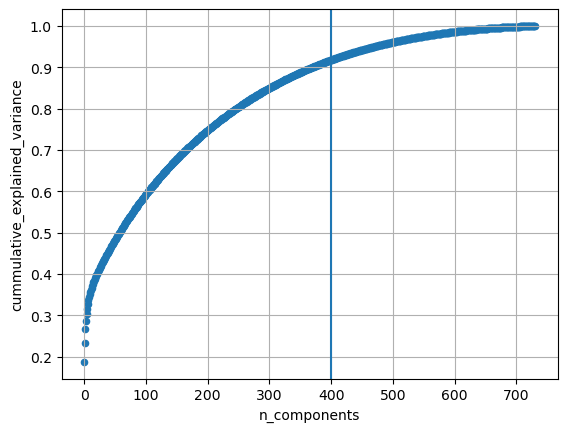

In [55]:
(
    pd.Series(projection_pipeline['pca'].explained_variance_ratio_)
        .cumsum()
        .to_frame()
        .reset_index()
        .rename(columns={'index': 'n_components', 0: 'cummulative_explained_variance'})
        .plot.scatter(x='n_components', y='cummulative_explained_variance')
)
plt.grid()
plt.axvline(N_PCS)

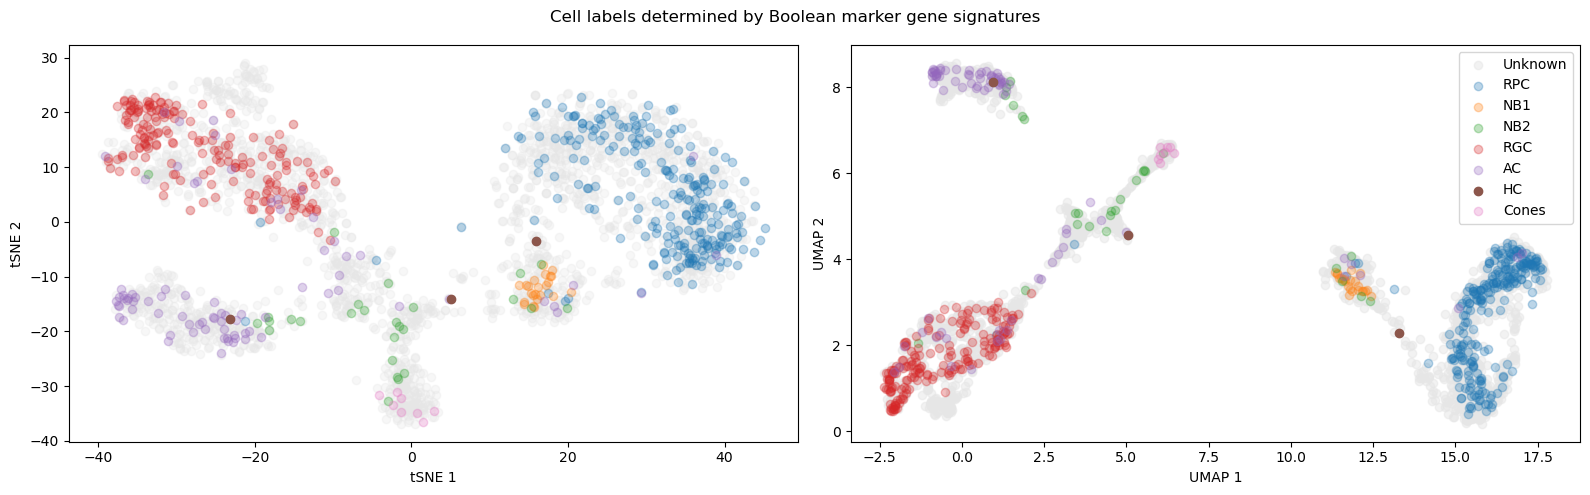

In [56]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(16,5))

_tsne_i = 0
_umap_i = 1
_ = axs[_umap_i].scatter(projected_umap.loc[unlabelled_idx, 0], projected_umap.loc[unlabelled_idx, 1], label="Unknown", alpha=.5, c=color_map["Unknown"])
for name, idx in unambiguous_observations.items():
        _x, _y = projected_umap.loc[idx, 0], projected_umap.loc[idx, 1]
        axs[_umap_i].scatter(_x, _y, label=name, alpha=1 if name == 'HC' else .3)#, c=color_map[name])

axs[_umap_i].set_xlabel("UMAP 1")
axs[_umap_i].set_ylabel("UMAP 2")
#axs[0].legend()

_xname = projected_tsne.columns[0]
_yname = projected_tsne.columns[1]
_ = axs[_tsne_i].scatter(projected_tsne.loc[unlabelled_idx, _xname], projected_tsne.loc[unlabelled_idx, _yname], label="Unknown", alpha=.3, c=color_map["Unknown"])
for name, idx in unambiguous_observations.items():
        _x, _y = projected_tsne.loc[idx, _xname], projected_tsne.loc[idx, _yname]
        axs[_tsne_i].scatter(_x, _y, label=name, alpha=1 if name == 'HC' else .3)#, c=color_map[name])
axs[_tsne_i].set_xlabel("tSNE 1")
axs[_tsne_i].set_ylabel("tSNE 2")
#axs[1].legend()
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.suptitle("Cell labels determined by Boolean marker gene signatures")
fig.tight_layout()

In [57]:
isolated_cells = (
    projected_umap
        .rename(columns={c: f"umap_{c}" for c in projected_umap.columns})
        .query("umap_0 > umap_0.mean() & umap_1 < 0")
        .index
)

In [58]:
print(f"{100*isolated_cells.shape[0]/data.shape[0]:.1f}% of cells are in this region/cluster")

0.0% of cells are in this region/cluster


In [59]:
isolated_cells_labels: set = set()
for name, idx in unambiguous_observations.items():
    if isolated_cells.isin(idx).any():
        isolated_cells_labels.update({name})
        
isolated_cells_labels

set()

## Clustering and label propagation

We will now look at unsupervised clustering (Leiden) which is common practice in scRNA-Seq.
We will use a voting scheme to label the unsupervised clusters: Each cluster recieves the label of the majority of cells within (we only consider cells which are actually labelled).
In this part, we use the `scanpy` package for scRNA-Seq analysis.

In [60]:
N_PCS = 400

In [61]:
from pipeline_config import ensure_corrected_h5ad

# integrate=true: wynik '2. Data Integration'; integrate=false: równoważna macierz bez ComBata zbudowana z merged_dataset.h5ad
adata = sc.read_h5ad(ensure_corrected_h5ad(cfg))
N_PCS = min(N_PCS, adata.n_vars - 1)  # PCA wymaga n_comps < liczba genów
adata

AnnData object with n_obs × n_vars = 2604 × 731
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mean', 'std'
    uns: 'log1p'
    layers: 'lognorm'

### Wczytanie poprawionej macierzy (batch + cykl komórkowy) zamiast surowego `dataset_hvgs.csv`

Klastrowanie Leiden niżej (na którym oprzemy etykietowanie majority-vote) liczyło się wcześniej wprost na `data` (log-normalizowane HVG z `dataset_hvgs.csv`), bez żadnej korekty. W `scHSC_herault` finalne, publikowane klastry (Fig. 1b) powstają dopiero **po** integracji batchy i `ScaleData(vars.to.regress = "G2M_score+S_score+G1_score")` (`R_src/Seurat3_integration.R:141-161`: integracja → regresja → PCA → UMAP/Leiden) — więc tu też PCA/klastrowanie ma iść na w pełni skorygowanych danych, nie na surowych.

`2. Data Integration.ipynb` produkuje teraz dokładnie taką macierz: `integrated_combat_corrected_expression.h5ad` — ten sam kanoniczny zestaw HVG co `dataset_hvgs.csv` (patrz `docs/scHSC_herault_cell_cycle_i_standaryzacja.md` §6), skorygowany o batch (`scanpy.pp.combat` — nie scanorama, bo `correct_scanpy` po drodze L2-normalizuje każdą komórkę i psuje analogię do `scale.data`, patrz §4) i o cykl komórkowy (`regress_out`+`scale`, ten sam mechanizm co dawniej liczony tutaj lokalnie — teraz przeniesiony do notebooka 2).

Wczytujemy ją tu zamiast budować `adata` z `data`. Binaryzacja scBoolSeq + dopasowanie markerowe w sekcji (a) wyżej zostają bez zmian, na surowym `dataset_hvgs.csv` — majority-vote niżej łączy je z klastrami Leiden po indeksie komórki, nie po zestawie genów, więc to nie przeszkadza.

**Dwuetapowe etykietowanie, nie cykl**: `2. Data Integration.ipynb` korzysta z **wstępnych** etykiet (`preliminary_cell_annotation_metadata.tsv`, transfer learning scVI/scArches z `1. Cell Annotation.ipynb`) do decyzji o `discard` *przed* integracją — nie z wyniku tego notebooka. Ten notebook liczy dopiero **finalne** etykiety (na już zintegrowanych/skorygowanych danych) i eksportuje je pod osobną nazwą, `cell_annotation_metadata.tsv` — te dwa pliki celowo się różnią, więc przepływ jest liniowy (1 → 2 → 3), bez cyklu. Patrz `docs/scHSC_herault_cell_cycle_i_standaryzacja.md` §5.

In [62]:
sc.pp.pca(adata, n_comps=N_PCS)

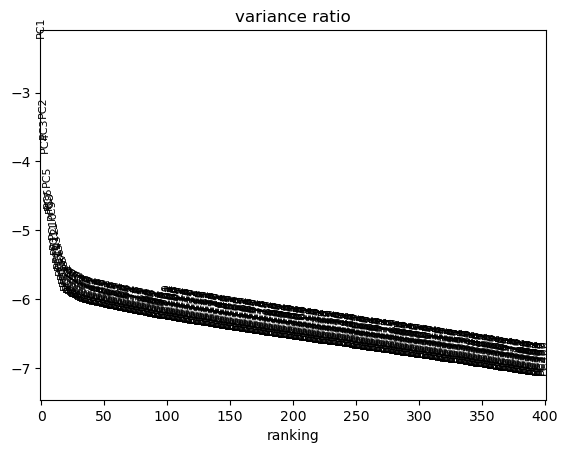

In [63]:
sc.pl.pca_variance_ratio(adata, log=True, n_pcs=N_PCS)

In [64]:
sc.pp.neighbors(adata, n_pcs=N_PCS)
sc.tl.umap(adata)
sc.tl.tsne(adata, n_pcs=N_PCS)

In [65]:
%%time
sc.tl.leiden(
    adata, key_added="leiden_res0_25", resolution=0.25, flavor="igraph", n_iterations=2
)
sc.tl.leiden(
    adata, key_added="leiden_res0_5", resolution=0.5, flavor="igraph", n_iterations=2
)
sc.tl.leiden(
    adata, key_added="leiden_res1", resolution=1.0, flavor="igraph", n_iterations=2
)

CPU times: user 130 ms, sys: 6.35 ms, total: 136 ms
Wall time: 135 ms


Here we visually compare which clusters were found with different resolutions of Leiden clusterization method.

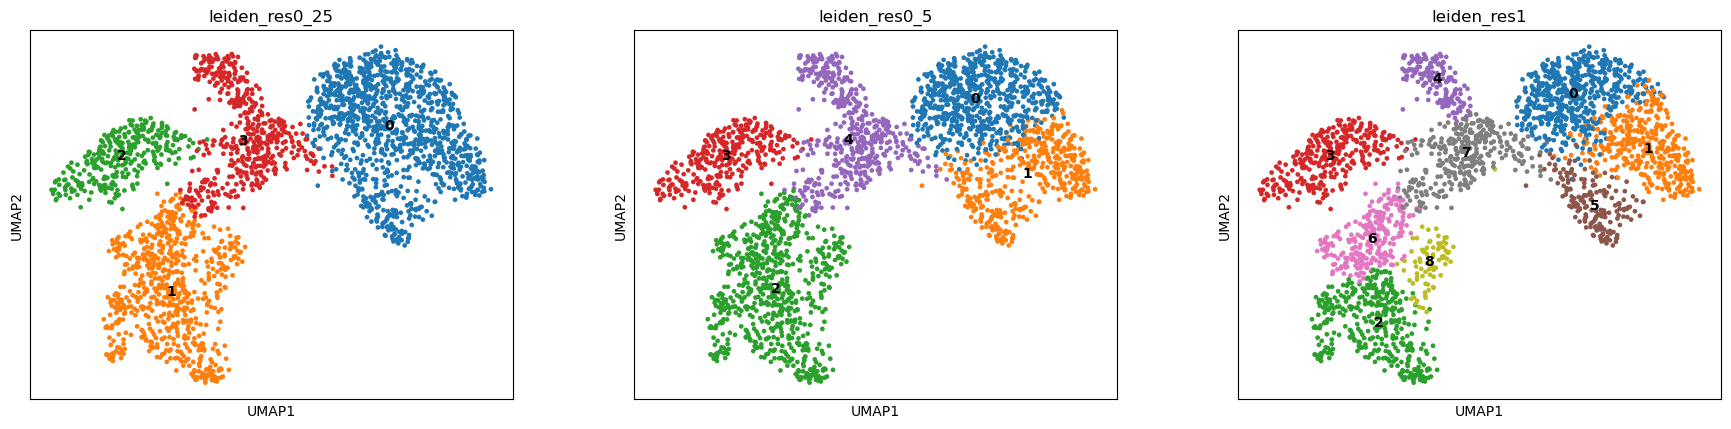

In [66]:
sc.pl.umap(
    adata,
    color=["leiden_res0_25", "leiden_res0_5", "leiden_res1"],
    legend_loc="on data",
)

In [67]:
sc.tl.leiden(
    adata, resolution=1.0, flavor="igraph", n_iterations=2
) # This execution is needed just for adata update with simple "leiden" named layer

In [68]:
100 * adata.obs.leiden.value_counts() / adata.n_obs

leiden
0    21.466974
2    14.669739
1    14.631336
3    11.981567
7    11.981567
6     9.408602
5     6.797235
4     6.029186
8     3.033794
Name: count, dtype: float64

In [69]:
# projected_umap/projected_tsne (sekcja a) to inny embedding na innej populacji
# komórek (14915, surowe 488 HVG) niż adata tutaj (14100, skorygowane 2000 HVG) —
# używamy embeddingów policzonych na tym samym adata, na którym liczyliśmy Leiden.
gg_umap = pd.DataFrame(
    adata.obsm["X_umap"], index=adata.obs_names, columns=["umap_1", "umap_2"]
).join(adata.obs.leiden)
gg_tsne = pd.DataFrame(
    adata.obsm["X_tsne"], index=adata.obs_names, columns=["t-SNE_1", "t-SNE_2"]
).join(adata.obs.leiden)

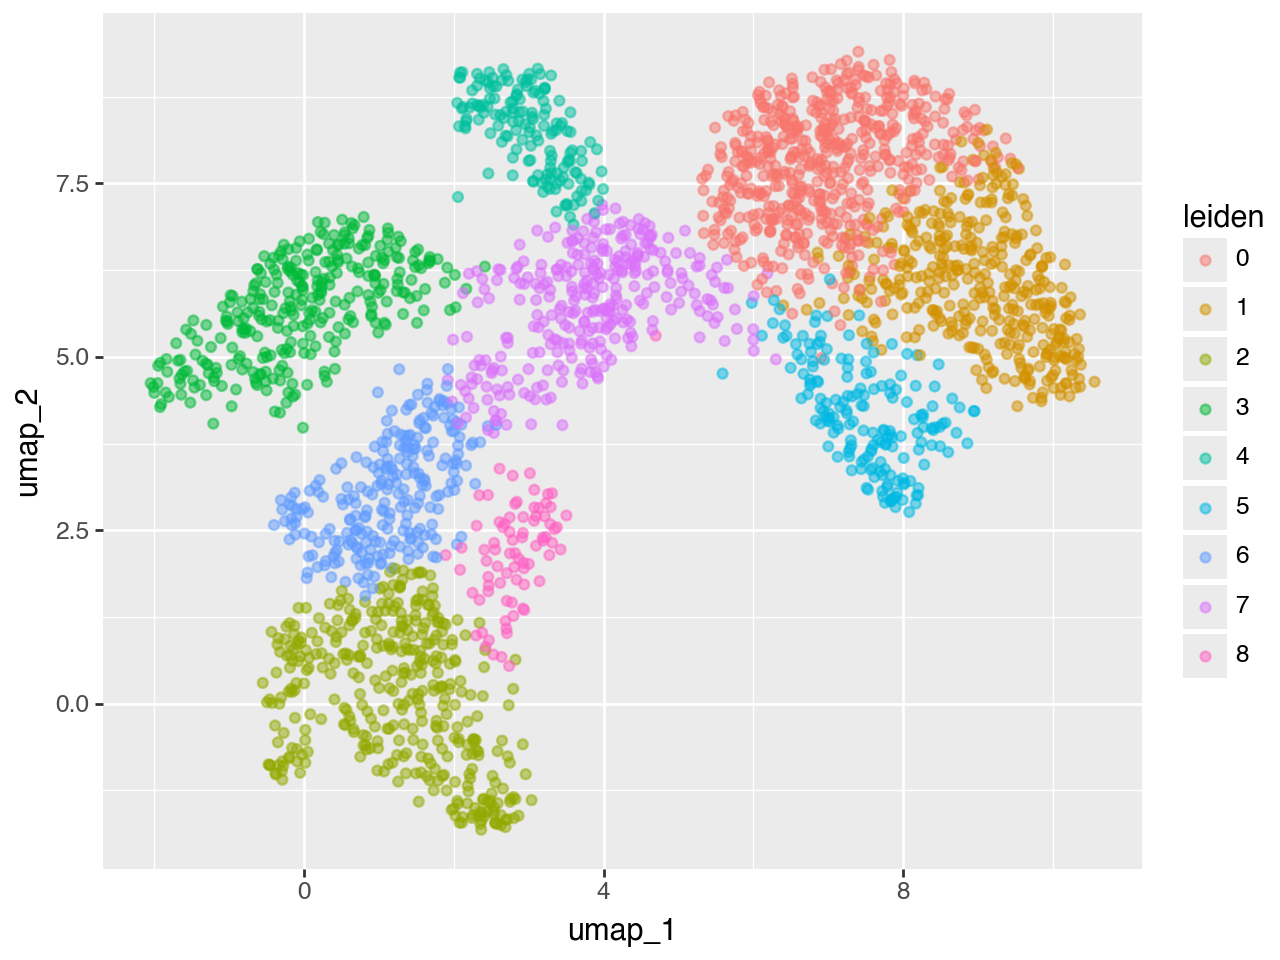

In [70]:
_plot_frame = gg_umap
first_plot = (
    ggplot(_plot_frame, aes(x=_plot_frame.columns[0], y=_plot_frame.columns[1]))
        + geom_point(aes(color='leiden'), alpha=.5)
)
first_plot

These 2 cells below look like something that might be not applicable to our data (was only needed specifically for original's paper data).

**Aktualizacja**: ten heurystyczny próg (konkretna ćwiartka UMAP: `umap_1 > mean & umap_2 < 0`) był dobrany wzrokowo dla starego, nieskorygowanego osadzenia na 488 genach. UMAP nie ma z góry ustalonej orientacji (dowolny obrót/odbicie między przebiegami, zwłaszcza na innym zestawie genów i innej korekcie danych), więc ten sam próg na nowym, skorygowanym 2000-genowym embeddingu może trafić w zupełnie inny (albo żaden sensowny) klaster. Zamiast ufać mu automatycznie, `discarded_leiden` niżej jest ustawione na `None` (nic nie jest odrzucane), dopóki ktoś nie zweryfikuje wzrokowo na wykresie UMAP wyżej, czy istnieje analogiczny klaster-artefakt i który to numer.

In [71]:
# Próg z poprzedniego (nieskorygowanego) embeddingu — patrz uwaga w komórce
# markdown wyżej. Zostawione tylko jako punkt odniesienia, nie ufamy mu ślepo.
_to_discard = _plot_frame.query("umap_1 > umap_1.mean() & umap_2 < 0").leiden.unique()
_to_discard

[], Categories (9, object): ['0', '1', '2', '3', ..., '5', '6', '7', '8']

In [72]:
# Nie ufamy automatycznie _to_discard[0] (patrz uwaga wyżej) — dopóki ktoś nie
# zweryfikuje wzrokowo, który klaster (jeśli jakikolwiek) faktycznie jest
# artefaktem na nowym embeddingu, nic nie oznaczamy jako discard.
discarded_leiden = None
discarded_leiden

In [73]:
pheno_by_cluster = {}
for clus, frame in _plot_frame.groupby('leiden'):
    louv_idx = frame.index
    pheno_by_cluster.update({
        clus: {
            pheno: louv_idx.isin(pheno_idx).sum()
            for pheno, pheno_idx
            in unambiguous_observations.items()
        }
    })

pheno_by_cluster

{'0': {'RPC': np.int64(103),
  'NB1': np.int64(1),
  'NB2': np.int64(0),
  'RGC': np.int64(0),
  'AC': np.int64(1),
  'HC': np.int64(0),
  'Cones': np.int64(0)},
 '1': {'RPC': np.int64(137),
  'NB1': np.int64(0),
  'NB2': np.int64(0),
  'RGC': np.int64(0),
  'AC': np.int64(1),
  'HC': np.int64(0),
  'Cones': np.int64(0)},
 '2': {'RPC': np.int64(0),
  'NB1': np.int64(0),
  'NB2': np.int64(1),
  'RGC': np.int64(122),
  'AC': np.int64(7),
  'HC': np.int64(0),
  'Cones': np.int64(0)},
 '3': {'RPC': np.int64(1),
  'NB1': np.int64(0),
  'NB2': np.int64(4),
  'RGC': np.int64(0),
  'AC': np.int64(49),
  'HC': np.int64(1),
  'Cones': np.int64(0)},
 '4': {'RPC': np.int64(0),
  'NB1': np.int64(0),
  'NB2': np.int64(3),
  'RGC': np.int64(0),
  'AC': np.int64(0),
  'HC': np.int64(0),
  'Cones': np.int64(8)},
 '5': {'RPC': np.int64(3),
  'NB1': np.int64(22),
  'NB2': np.int64(5),
  'RGC': np.int64(0),
  'AC': np.int64(5),
  'HC': np.int64(0),
  'Cones': np.int64(0)},
 '6': {'RPC': np.int64(1),
  'NB

These are the number of observations matching each one of the labels, for every louvain cluster.

In [74]:
majority_pheno_by_cluster = {}
for clus, votes in pheno_by_cluster.items():
    votes = sorted(votes.items(), key=lambda item: item[1], reverse=True)
    _total = sum(v for _, v in votes)
    relative_votes = [(name, v/_total) for name, v in votes] 
    print(clus, relative_votes)
    majority_pheno_by_cluster.update({clus: relative_votes[0][0]})

0 [('RPC', np.float64(0.9809523809523809)), ('NB1', np.float64(0.009523809523809525)), ('AC', np.float64(0.009523809523809525)), ('NB2', np.float64(0.0)), ('RGC', np.float64(0.0)), ('HC', np.float64(0.0)), ('Cones', np.float64(0.0))]
1 [('RPC', np.float64(0.9927536231884058)), ('AC', np.float64(0.007246376811594203)), ('NB1', np.float64(0.0)), ('NB2', np.float64(0.0)), ('RGC', np.float64(0.0)), ('HC', np.float64(0.0)), ('Cones', np.float64(0.0))]
2 [('RGC', np.float64(0.9384615384615385)), ('AC', np.float64(0.05384615384615385)), ('NB2', np.float64(0.007692307692307693)), ('RPC', np.float64(0.0)), ('NB1', np.float64(0.0)), ('HC', np.float64(0.0)), ('Cones', np.float64(0.0))]
3 [('AC', np.float64(0.8909090909090909)), ('NB2', np.float64(0.07272727272727272)), ('RPC', np.float64(0.01818181818181818)), ('HC', np.float64(0.01818181818181818)), ('NB1', np.float64(0.0)), ('RGC', np.float64(0.0)), ('Cones', np.float64(0.0))]
4 [('Cones', np.float64(0.7272727272727273)), ('NB2', np.float64(0.2

Here we selected the majority label for each one of the clusters.

In [75]:
represented_by_leiden = set(majority_pheno_by_cluster.values())
phenotypes = set(unambiguous_observations)

In [76]:
100 * len(represented_by_leiden.intersection(phenotypes)) / len(phenotypes)

85.71428571428571

In [77]:
phenotypes.difference(represented_by_leiden)

{'HC'}

In [78]:
_new_plot = _plot_frame.join(_plot_frame.leiden.map(majority_pheno_by_cluster).to_frame().rename(columns={"leiden": "phenotype"}))
_new_plot.head()

,umap_1,umap_2,leiden,phenotype
Lane1_AAACCTGAGATGTCGG,6.854671,7.526310,0,RPC
Lane1_AAACCTGCAATCCAAC,6.279358,7.633167,0,RPC
Lane1_AAACCTGGTTCCTCCA,1.336018,-0.012991,2,RGC
Lane1_AAACCTGTCCAATGGT,2.416223,6.301172,3,AC
Lane1_AAACGGGAGGCAATTA,10.027819,5.167701,1,RPC


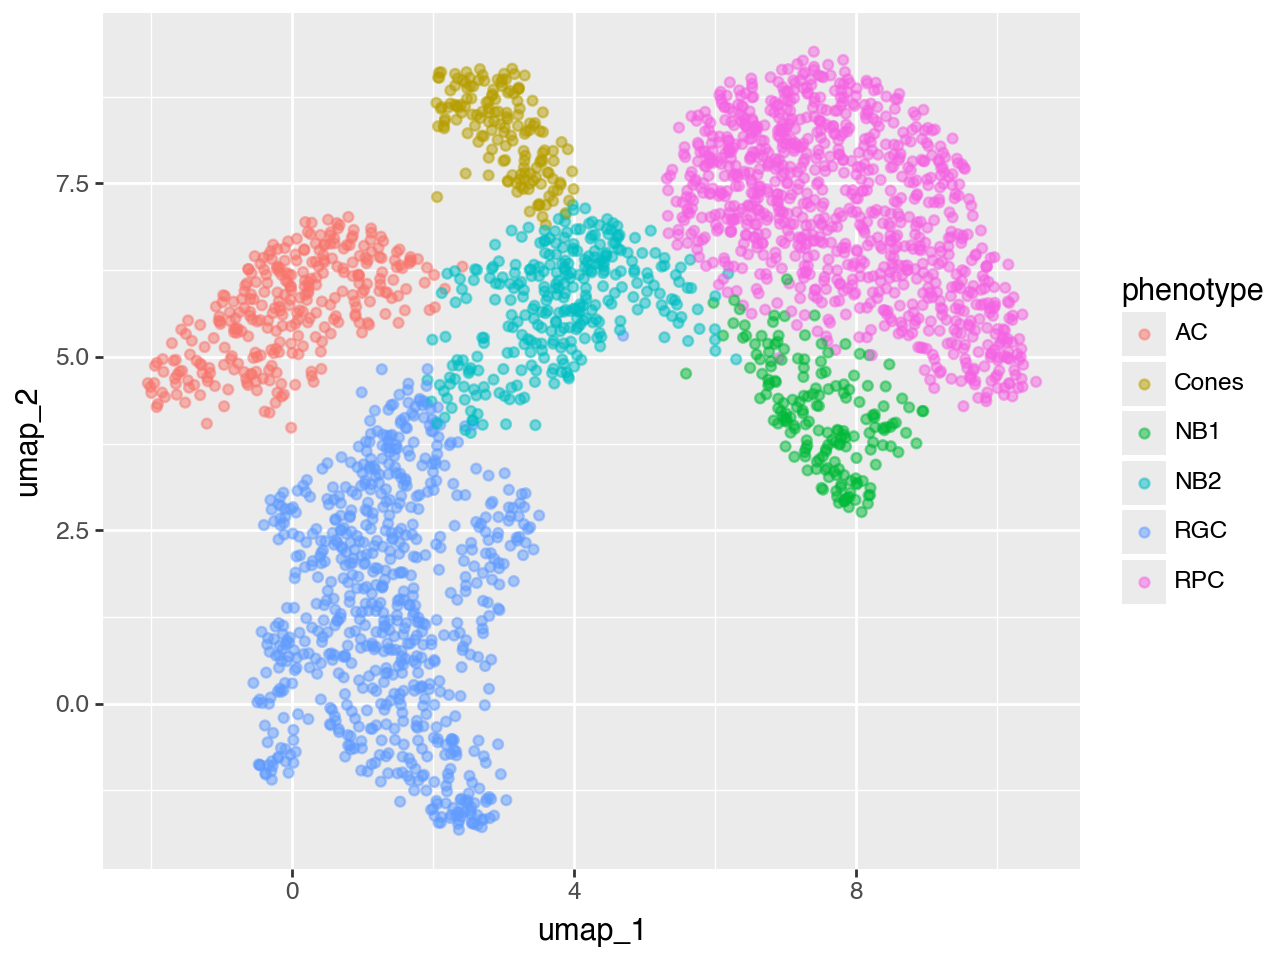

In [79]:
second_plot = (
    ggplot(_new_plot, aes(x=_plot_frame.columns[0], y=_plot_frame.columns[1]))
        + geom_point(aes(color='phenotype'), alpha=.5)
)
second_plot

Here we can see the final result of the binarization-based annotation method.

In [80]:
palette = sns.color_palette('Set2', _plot_frame.leiden.unique().shape[0])
palette.as_hex()

['#66c2a5',
 '#fc8d62',
 '#8da0cb',
 '#e78ac3',
 '#a6d854',
 '#ffd92f',
 '#e5c494',
 '#b3b3b3',
 '#66c2a5']

In [81]:
final_color_map = dict(zip(_new_plot.phenotype.unique(),palette.as_hex()))
final_color_map

{'RPC': '#66c2a5',
 'RGC': '#fc8d62',
 'AC': '#8da0cb',
 'Cones': '#e78ac3',
 'NB2': '#a6d854',
 'NB1': '#ffd92f'}

In [82]:
metadata = pd.DataFrame({
    'label': _new_plot.phenotype,
    'label_color': _new_plot.phenotype.map(final_color_map),
    'leiden': _new_plot.leiden,
})
metadata.loc[:, 'discard'] = False
metadata.loc[metadata.leiden == discarded_leiden, 'discard'] = True
metadata.head()

,label,label_color,leiden,discard
Lane1_AAACCTGAGATGTCGG,RPC,#66c2a5,0,False
Lane1_AAACCTGCAATCCAAC,RPC,#66c2a5,0,False
Lane1_AAACCTGGTTCCTCCA,RGC,#fc8d62,2,False
Lane1_AAACCTGTCCAATGGT,AC,#8da0cb,3,False
Lane1_AAACGGGAGGCAATTA,RPC,#66c2a5,1,False


In [83]:
metadata.discard.value_counts()

discard
False    2604
Name: count, dtype: int64

## Exporting metadata (**annotated cell types**)

Here we export the obtained data, to use it for integration/trajectory inference.

In [84]:
metadata.to_csv(cfg.path("cell_annotation_tsv"), sep="\t")

In [85]:
metadata

,label,label_color,leiden,discard
Lane1_AAACCTGAGATGTCGG,RPC,#66c2a5,0,False
Lane1_AAACCTGCAATCCAAC,RPC,#66c2a5,0,False
Lane1_AAACCTGGTTCCTCCA,RGC,#fc8d62,2,False
Lane1_AAACCTGTCCAATGGT,AC,#8da0cb,3,False
Lane1_AAACGGGAGGCAATTA,RPC,#66c2a5,1,False
...,...,...,...,...
Lane1_TTTGTCACAGCTGTTA,RPC,#66c2a5,0,False
Lane1_TTTGTCAGTAAGAGGA,NB1,#ffd92f,5,False
Lane1_TTTGTCATCCCACTTG,RPC,#66c2a5,1,False
Lane1_TTTGTCATCCCATTTA,RPC,#66c2a5,0,False
